# 37. Randomized Linear Algebra and Matrix Concentration
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Monte Carlo approximation of $AA^{\mathsf T}$ for a $100\times5000$ matrix whose columns have very different norms. The relative Frobenius error against the number $s$ of sampled columns, for uniform sampling (grey) and norm-squared sampling $p_j\propto\lVert a_j\rVert^2$ (blue), averaged over $20$ trials, with the predicted $1/\sqrt s$ slope (dashed). Importance sampling wins by a constant factor that grows with the spread of column norms.

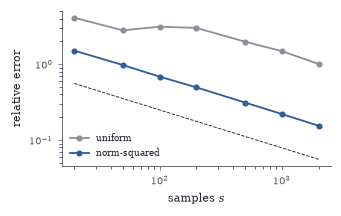

In [2]:
rng = np.random.default_rng(0); m, n = 100, 5000; A = rng.normal(size=(m, n)) * rng.lognormal(0, 1.2, n)[None, :]          # columns with very different norms
G = A @ A.T; nrm2 = (A**2).sum(0); ss = [20, 50, 100, 200, 500, 1000, 2000]
def est(p, s):
    idx = rng.choice(n, s, p=p); C = A[:, idx] / np.sqrt(s * p[idx]); return np.linalg.norm(C @ C.T - G) / np.linalg.norm(G)
fig, ax = plt.subplots(figsize=(W * 0.65, 1.85))
for p, col, lab in [(np.full(n, 1 / n), GRAY, "uniform"), (nrm2 / nrm2.sum(), BLUE, "norm-squared")]:
    errs = [np.mean([est(p, s) for _ in range(20)]) for s in ss]; ax.loglog(ss, errs, "o-", ms=3, color=col, label=lab)
ax.loglog(ss, 2.5 / np.sqrt(ss), "--", color=INK, lw=0.6); ax.set_xlabel("samples $s$"); ax.set_ylabel("relative error"); ax.legend(fontsize=6)

The Johnson–Lindenstrauss lemma in practice. $N=300$ random points in $\mathbb{R}^{2000}$ projected by Gaussian maps to $k$ dimensions; the distribution of distortions $\lVert Sx_i-Sx_j\rVert^2/\lVert x_i-x_j\rVert^2$ over all $44850$ pairs (left, for $k=20,100,500$) narrows like $1/\sqrt k$, and the largest distortion (right, blue) follows $\sqrt{(\log N)/k}$ (dashed), independent of the ambient dimension.

Text(0, 0.5, 'max distortion')

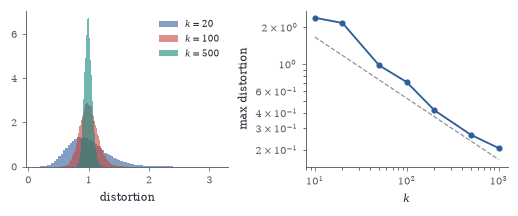

In [3]:
rng = np.random.default_rng(1); N, n = 300, 2000; X = rng.normal(size=(N, n)) * rng.uniform(0.5, 2, n)[None, :]
iu = np.triu_indices(N, 1)
sq = (X**2).sum(1); D0 = (sq[:, None] + sq[None, :] - 2 * X @ X.T)[iu]
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85))
ks = [10, 20, 50, 100, 200, 500, 1000]; worst = []
for k in ks:
    S = rng.normal(size=(n, k)) / np.sqrt(k); Y = X @ S; sy = (Y**2).sum(1); ratio = (sy[:, None] + sy[None, :] - 2 * Y @ Y.T)[iu] / D0; worst.append(np.abs(ratio - 1).max())
    if k in (20, 100, 500): axs[0].hist(ratio, bins=80, density=True, alpha=0.6, label=f"$k={k}$")
axs[0].set_xlabel("distortion"); axs[0].legend(fontsize=6)
axs[1].loglog(ks, worst, "o-", color=BLUE, ms=3); axs[1].loglog(ks, 2.2 * np.sqrt(np.log(N) / np.array(ks)), "--", color=GRAY, lw=0.8); axs[1].set_xlabel("$k$"); axs[1].set_ylabel("max distortion")

Randomized SVD on a $1000\times800$ matrix with slowly decaying singular values $\sigma_j=j^{-1/2}$ (a hard case). Operator-norm error of the randomized rank-$k$ SVD (sketch of size $k+10$, truncated to rank $k$) against $k$, for $q=0,1,2$ power iterations (colours), compared with the optimal error $\sigma_{k+1}$ (black). Without power iterations the error stalls well above optimal; two power iterations nearly reach it.

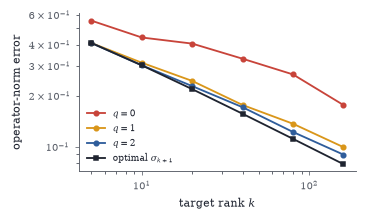

In [4]:
rng = np.random.default_rng(2); m, n = 1000, 800; U0, _ = np.linalg.qr(rng.normal(size=(m, n))); V0, _ = np.linalg.qr(rng.normal(size=(n, n))); sig = np.arange(1, n + 1) ** -0.5
A = (U0 * sig) @ V0.T; ks = [5, 10, 20, 40, 80, 160]; p = 10
def rangefinder(A, l, q):
    Y = A @ rng.normal(size=(A.shape[1], l)); Q, _ = np.linalg.qr(Y)
    for _ in range(q): Q, _ = np.linalg.qr(A.T @ Q); Q, _ = np.linalg.qr(A @ Q)
    return Q
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
for q, col in [(0, RED), (1, GOLD), (2, BLUE)]:
    errs = []
    for k in ks:
        Q = rangefinder(A, k + p, q); Ub, sb, Vbt = np.linalg.svd(Q.T @ A, full_matrices=False)      # small SVD, truncated to rank k
        errs.append(np.linalg.norm(A - (Q @ Ub[:, :k]) * sb[:k] @ Vbt[:k], 2))
    ax.loglog(ks, errs, "o-", ms=3, color=col, label=f"$q={q}$")
ax.loglog(ks, sig[np.array(ks)], "s-", color=INK, ms=3, label=r"optimal $\sigma_{k+1}$"); ax.set_xlabel("target rank $k$"); ax.set_ylabel("operator-norm error"); ax.legend(fontsize=6)

Nyström approximation of a Gaussian kernel matrix on $2000$ points in the plane. Relative trace-norm error $\mathrm{tr}(K-\hat K)/\mathrm{tr}K$ against the number of sampled columns $l$, for uniform column sampling (grey), for a Gaussian sketch (gold), and for the best rank-$l$ approximation (black, unattainable without computing the whole eigendecomposition). The error $K-\hat K$ is a Schur complement, so it is positive semidefinite and its trace is a natural measure.

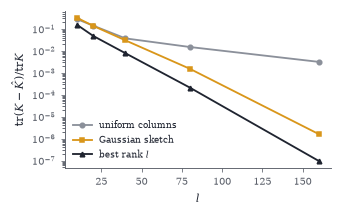

In [5]:
rng = np.random.default_rng(3); n = 2000; P = np.r_[rng.normal(size=(n // 2, 2)) * 0.6, rng.normal(size=(n // 2, 2)) * 0.3 + [2, 1]]
sqd = (P**2).sum(1); Kg = np.exp(-(sqd[:, None] + sqd[None, :] - 2 * P @ P.T) / (2 * 0.5**2)); ev = np.sort(np.linalg.eigvalsh(Kg))[::-1]; trK = np.trace(Kg)
ls = [10, 20, 40, 80, 160]; unif, gaus = [], []
for l in ls:
    J = rng.choice(n, l, replace=False); C = Kg[:, J]; Kh = C @ np.linalg.pinv(Kg[np.ix_(J, J)], rcond=1e-12) @ C.T; unif.append(np.trace(Kg - Kh) / trK)
    Om = rng.normal(size=(n, l)); Y = Kg @ Om; Kh2 = Y @ np.linalg.pinv(Om.T @ Y, rcond=1e-12) @ Y.T; gaus.append(np.trace(Kg - Kh2) / trK)
fig, ax = plt.subplots(figsize=(W * 0.65, 1.85))
ax.semilogy(ls, unif, "o-", color=GRAY, ms=3, label="uniform columns"); ax.semilogy(ls, gaus, "s-", color=GOLD, ms=3, label="Gaussian sketch")
ax.semilogy(ls, [ev[l:].sum() / trK for l in ls], "^-", color=INK, ms=3, label="best rank $l$"); ax.set_xlabel("$l$"); ax.set_ylabel(r"$\mathrm{tr}(K-\hat K)/\mathrm{tr}K$"); ax.legend(fontsize=6)

Interpolative decomposition by column-pivoted QR for a $200\times300$ matrix with decaying singular values. For each $k$, choose $k$ columns by pivoted QR, approximate $A\approx A_{:,J}X$ by least squares, and record the operator-norm error (blue) against the optimal rank-$k$ error $\sigma_{k+1}$ (black) and the error of $k$ uniformly random columns (grey). Pivoted columns are nearly as good as singular vectors, and they are actual columns of the data.

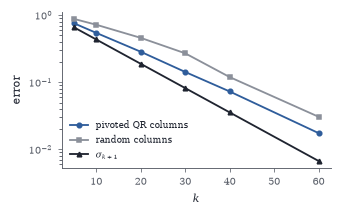

In [6]:
from scipy.linalg import qr as scipy_qr
rng = np.random.default_rng(4); m, n = 200, 300; U0, _ = np.linalg.qr(rng.normal(size=(m, m))); V0, _ = np.linalg.qr(rng.normal(size=(n, m)))
sig = np.exp(-np.arange(m) / 12); A = (U0 * sig) @ V0.T; ks = [5, 10, 20, 30, 40, 60]
def id_err(J):
    C = A[:, J]; X, *_ = np.linalg.lstsq(C, A, rcond=None); return np.linalg.norm(A - C @ X, 2)
_, _, piv = scipy_qr(A, pivoting=True, mode="economic")
fig, ax = plt.subplots(figsize=(W * 0.65, 1.85))
ax.semilogy(ks, [id_err(piv[:k]) for k in ks], "o-", color=BLUE, ms=3, label="pivoted QR columns")
ax.semilogy(ks, [np.median([id_err(rng.choice(n, k, replace=False)) for _ in range(10)]) for k in ks], "s-", color=GRAY, ms=3, label="random columns")
ax.semilogy(ks, sig[np.array(ks)], "^-", color=INK, ms=3, label=r"$\sigma_{k+1}$"); ax.set_xlabel("$k$"); ax.set_ylabel("error"); ax.legend(fontsize=6)

Matrix concentration. Sampling $s$ rows of an $m\times n$ orthonormal matrix $Q$ ($m=5000$, $n=20$) by leverage scores, the deviation $\lVert(SQ)^{\mathsf T}(SQ)-I\rVert$ (blue, median of $20$ trials) decays like $\sqrt{n\log n/s}$ (dashed), as the matrix Bernstein inequality predicts. Uniform sampling (grey) on a coherent $Q$ (a few rows with large leverage) is far worse.

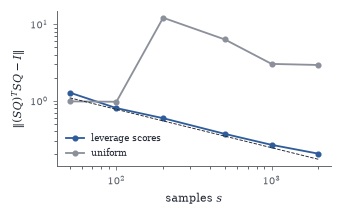

In [7]:
rng = np.random.default_rng(5); mq, nq = 5000, 20; G = rng.normal(size=(mq, nq)); G[:nq] *= 40; Qc, _ = np.linalg.qr(G); lev = (Qc**2).sum(1)
ss = [50, 100, 200, 500, 1000, 2000]
def dev(p, s):
    idx = rng.choice(mq, s, p=p); SQ = Qc[idx] / np.sqrt(s * p[idx])[:, None]; return np.linalg.norm(SQ.T @ SQ - np.eye(nq), 2)
fig, ax = plt.subplots(figsize=(W * 0.65, 1.85))
for p, col, lab in [(lev / nq, BLUE, "leverage scores"), (np.full(mq, 1 / mq), GRAY, "uniform")]:
    ax.loglog(ss, [np.median([dev(p, s) for _ in range(20)]) for s in ss], "o-", ms=3, color=col, label=lab)
ax.loglog(ss, np.sqrt(nq * np.log(nq) / np.array(ss)), "--", color=INK, lw=0.6); ax.set_xlabel("samples $s$"); ax.set_ylabel(r"$\|(SQ)^{T}SQ-I\|$"); ax.legend(fontsize=6)

Random Fourier features for the Gaussian kernel on $500$ points in $\mathbb{R}^5$. Relative operator-norm error $\lVert ZZ^{\mathsf T}-K\rVert/\lVert K\rVert$ against the number of features $D$ (blue, median over $10$ draws), decaying like $1/\sqrt D$ (dashed). Inset: kernel values $k(x_i,x_j)$ against their random-feature estimates for $D=2000$.

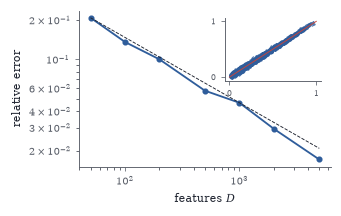

In [8]:
rng = np.random.default_rng(6); nk, dk = 500, 5; Xk = rng.normal(size=(nk, dk)); sqk = (Xk**2).sum(1); Kk = np.exp(-(sqk[:, None] + sqk[None, :] - 2 * Xk @ Xk.T) / (2 * 2.0**2))
Ds = [50, 100, 200, 500, 1000, 2000, 5000]
def rff(D):
    Om = rng.normal(size=(dk, D)) / 2.0; bb = rng.uniform(0, 2 * np.pi, D); return np.sqrt(2 / D) * np.cos(Xk @ Om + bb)
def rff_err(D):
    Z = rff(D); return np.linalg.norm(Z @ Z.T - Kk, 2) / np.linalg.norm(Kk, 2)
errs = [np.median([rff_err(D) for _ in range(10)]) for D in Ds]
fig, ax = plt.subplots(figsize=(W * 0.65, 1.85))
ax.loglog(Ds, errs, "o-", color=BLUE, ms=3); ax.loglog(Ds, errs[0] * np.sqrt(Ds[0] / np.array(Ds)), "--", color=INK, lw=0.6); ax.set_xlabel("features $D$"); ax.set_ylabel("relative error")
ins = ax.inset_axes([0.58, 0.55, 0.38, 0.4]); Z = rff(2000); iu = np.triu_indices(nk, 1); sel = rng.choice(len(iu[0]), 3000)
ins.plot(Kk[iu][sel], (Z @ Z.T)[iu][sel], ".", ms=0.8, color=BLUE); ins.plot([0, 1], [0, 1], color=RED, lw=0.6); ins.set_xticks([0, 1]); ins.set_yticks([0, 1]); ins.tick_params(labelsize=5)

In [9]:
rng = np.random.default_rng(0); eps = 0.2
for k in (20, 50, 100, 200):
    v = rng.chisquare(k, 200000) / k; print(f"k={k:3d}: empirical {np.mean(np.abs(v - 1) > eps):.4f}   bound {2 * np.exp(-k * (eps**2 - eps**3) / 4):.4f}")

k= 20: empirical 0.5267   bound 1.7043
k= 50: empirical 0.3137   bound 1.3406
k=100: empirical 0.1535   bound 0.8987
k=200: empirical 0.0452   bound 0.4038


In [10]:
rng = np.random.default_rng(1); Qs, _ = np.linalg.qr(rng.normal(size=(2000, 10)))
for k in (20, 50, 200):
    sv = np.linalg.svd(rng.normal(size=(k, 2000)) / np.sqrt(k) @ Qs, compute_uv=False); print(f"k={k:3d}: singular values in [{sv.min():.3f}, {sv.max():.3f}]   prediction 1 -/+ sqrt(10/k) = [{1 - np.sqrt(10 / k):.3f}, {1 + np.sqrt(10 / k):.3f}]")

k= 20: singular values in [0.370, 1.438]   prediction 1 -/+ sqrt(10/k) = [0.293, 1.707]
k= 50: singular values in [0.604, 1.350]   prediction 1 -/+ sqrt(10/k) = [0.553, 1.447]
k=200: singular values in [0.820, 1.201]   prediction 1 -/+ sqrt(10/k) = [0.776, 1.224]


In [11]:
import time
rng = np.random.default_rng(2); m, n = 20000, 50; A = rng.normal(size=(m, n)); b = A @ rng.normal(size=n) + rng.normal(size=m)
t0 = time.perf_counter(); x_ls, *_ = np.linalg.lstsq(A, b, rcond=None); t1 = time.perf_counter()
S = rng.normal(size=(500, m)) / np.sqrt(500); xs, *_ = np.linalg.lstsq(S @ A, S @ b, rcond=None); t2 = time.perf_counter()
print(f"exact residual {np.linalg.norm(A @ x_ls - b):.3f}   sketched residual {np.linalg.norm(A @ xs - b):.3f}   ratio {np.linalg.norm(A @ xs - b) / np.linalg.norm(A @ x_ls - b):.4f}")

exact residual 141.388   sketched residual 148.961   ratio 1.0536


In [12]:
def rsvd(A, k, p=10, q=1, rng=np.random.default_rng(3)):
    Q, _ = np.linalg.qr(A @ rng.normal(size=(A.shape[1], k + p)))
    for _ in range(q): Q, _ = np.linalg.qr(A.T @ Q); Q, _ = np.linalg.qr(A @ Q)
    Ub, s, Vt = np.linalg.svd(Q.T @ A, full_matrices=False); return Q @ Ub[:, :k], s[:k], Vt[:k]
rng = np.random.default_rng(4); L = rng.normal(size=(2000, 50)) @ rng.normal(size=(50, 1000)); A = L + 0.5 * rng.normal(size=(2000, 1000))
U, s, Vt = rsvd(A, 50); s_true = np.linalg.svd(A, compute_uv=False)[:50]
print("max relative error in the top 50 singular values:", f"{np.max(np.abs(s - s_true) / s_true):.2e}")

max relative error in the top 50 singular values: 2.18e-08
